# FraudLens: exploratory data analysis

**Question for this notebook:** before any model is trained, what in this data could mislead us, and what in it can a triage model actually use?

Each section ends with *what we did about it*, and every claim is backed by the output of the cell above it.

Dataset: [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) (ULB Machine Learning Group), card transactions by European cardholders over two days in September 2013. `V1`-`V28` are PCA components the issuer published in place of the confidential raw fields; only `Time` and `Amount` are in original units.

In [1]:
%matplotlib inline
import sys

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from fraudlens import config, data
from fraudlens.features import hour_of_day
from fraudlens.figures import BLUE, GREY, INK, MUTED, ORANGE, style

style()
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)
COLUMNS = [*config.RAW_FEATURES, config.TARGET]

raw = data.load_raw()
print(f"{len(raw):,} transactions x {len(COLUMNS)} columns | missing values: {int(raw[COLUMNS].isna().sum().sum())}")
raw.head(3)

284,807 transactions x 31 columns | missing values: 0


,txn_id,Time,V1,V2,V3,V4,V5,V6,V7,V8,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


## 1. Fraud is so rare that accuracy is meaningless

The first number anyone computes on this data is accuracy, and it is a trap.

In [2]:
fraud, total = int(raw["Class"].sum()), len(raw)
print(f"Fraud: {fraud:,} of {total:,} transactions = {fraud / total:.3%}")
print(f"A 'model' that always answers 'not fraud' is {1 - fraud / total:.2%} accurate and catches 0 of {fraud} frauds.")

Fraud: 492 of 284,807 transactions = 0.173%
A 'model' that always answers 'not fraud' is 99.83% accurate and catches 0 of 492 frauds.


**What we did about it.** Accuracy is never used to judge a model here. The headline metrics are PR-AUC (area under the precision-recall curve) and precision and recall *among the 200 alerts the team can review*. ROC-AUC is reported only to show how much it flatters: with 99.8% negatives, a tiny false-positive rate still means hundreds of false alarms.

## 2. The file contains exact duplicate transactions

The brief does not mention this one. If the same row can sit in both the training and the test set, the model gets graded on something it has already seen.

In [3]:
dup = raw.duplicated(subset=COLUMNS, keep="first")
print(f"Exact duplicate rows: {int(dup.sum()):,}, of which fraud: {int(raw.loc[dup, 'Class'].sum())}")

# How bad is it under the usual random 75/25 split? Count test rows with an identical twin in train.
train_idx, test_idx = train_test_split(raw.index, test_size=0.25, stratify=raw["Class"], random_state=config.SEED)
row_hash = pd.util.hash_pandas_object(raw[COLUMNS], index=False)
has_twin = row_hash.loc[test_idx].isin(row_hash.loc[train_idx])
print(f"Random split: {int(has_twin.sum()):,} test rows are exact copies of a training row, "
      f"{int(raw.loc[test_idx, 'Class'][has_twin].sum())} of them fraud.")

clean, report = data.clean(raw)
print(f"After removing duplicates: {report['rows_clean']:,} rows, {report['fraud_clean']} frauds.")

Exact duplicate rows: 1,081, of which fraud: 19


Random split: 403 test rows are exact copies of a training row, 9 of them fraud.


After removing duplicates: 283,726 rows, 473 frauds.


**What we did about it.** `fraudlens.data.clean` drops exact duplicates before any split. The split we use for the headline result is by day, which also makes it impossible for copies to straddle it (identical rows share the same `Time`).

## 3. Two days of data, and a ceiling set by capacity rather than by the model

The client reviews **200 alerts per day**. The file covers two days, so the honest test is: learn from day 1, then build the day-2 queue.

In [4]:
per_day = (
    clean.assign(fraud_amount=clean["Amount"] * clean["Class"])
    .groupby("day")
    .agg(transactions=("Class", "size"), frauds=("Class", "sum"), fraud_value_eur=("fraud_amount", "sum"))
)
per_day["fraud_rate_%"] = (100 * per_day["frauds"] / per_day["transactions"]).round(3)
per_day["best_possible_recall_with_200_alerts_%"] = (100 * (200 / per_day["frauds"]).clip(upper=1)).round(1)
per_day["fraud_value_eur"] = per_day["fraud_value_eur"].round(0)
per_day

,transactions,frauds,fraud_value_eur,fraud_rate_%,best_possible_recall_with_200_alerts_%
day,,,,,
1,144236,272,32469.0,0.189,73.5
2,139490,201,26122.0,0.144,99.5


**What we did about it.**

- Training uses day 1 only; day 2 is scored once, at the end, as the unseen day. No look-ahead.
- On a day like day 1 there are more frauds than review slots, so even a *perfect* model could not catch them all with 200 reviews. Recall is capped by staffing. The app's capacity planner shows what each extra review buys.

## 4. Fraud is small: the biggest transactions are the wrong place to look

In [5]:
summary = clean.groupby("Class")["Amount"].describe(percentiles=[0.5, 0.9, 0.99]).round(2)
summary.index = ["genuine", "fraud"]
display(summary[["count", "50%", "mean", "90%", "99%", "max"]])

frauds = clean[clean["Class"] == 1]
top_amounts = frauds["Amount"].round(2).value_counts().head(4)
print("Most common fraud amounts (EUR):")
for amount, n in top_amounts.items():
    print(f"  {amount:>7.2f}  x{n:<4} = {n / len(frauds):.0%} of all frauds")

day2 = clean[clean["day"] == 2]
caught = int(day2.nlargest(200, "Amount")["Class"].sum())
print(f"\nReviewing the 200 largest transactions of day 2 catches {caught} of {int(day2['Class'].sum())} frauds.")
print(f"Reviewing 200 at random would catch {200 * day2['Class'].mean():.1f} on average.")

,count,50%,mean,90%,99%,max
genuine,283253.0,22.00,88.41,203.00,1018.06,25691.16
fraud,473.0,9.82,123.87,348.65,1364.14,2125.87


Most common fraud amounts (EUR):
     1.00  x105  = 22% of all frauds
    99.99  x27   = 6% of all frauds
     0.00  x25   = 5% of all frauds
     0.76  x17   = 4% of all frauds

Reviewing the 200 largest transactions of day 2 catches 0 of 201 frauds.
Reviewing 200 at random would catch 0.3 on average.


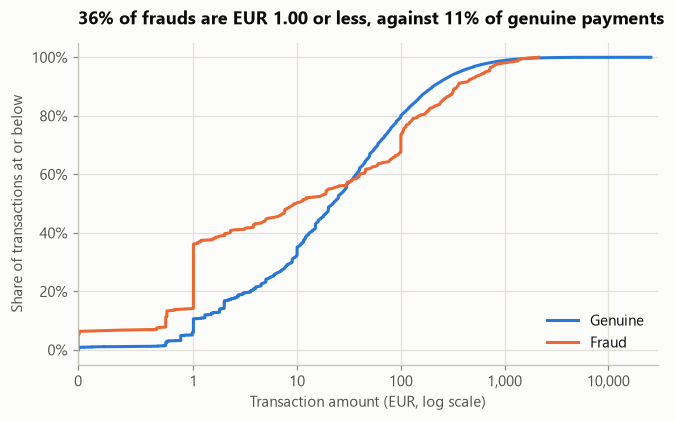

In [6]:
fig, ax = plt.subplots(figsize=(6.8, 3.8))
for label, colour, part in (("Genuine", BLUE, clean[clean["Class"] == 0]), ("Fraud", ORANGE, frauds)):
    amounts = np.sort(part["Amount"].to_numpy())
    ax.plot(amounts, np.arange(1, len(amounts) + 1) / len(amounts), color=colour, linewidth=2, label=label)
ax.set_xscale("symlog", linthresh=1)
ax.set_xlim(0, 30_000)
ax.set_xticks([0, 1, 10, 100, 1_000, 10_000], ["0", "1", "10", "100", "1,000", "10,000"])
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Transaction amount (EUR, log scale)")
ax.set_ylabel("Share of transactions at or below")
ax.set_title(f"{(frauds['Amount'] <= 1).mean():.0%} of frauds are EUR 1.00 or less, against {(clean.loc[clean['Class'] == 0, 'Amount'] <= 1).mean():.0%} of genuine payments")
ax.legend(loc="lower right")
fig.savefig(FIG / "eda_amount.png")
plt.show()

**What we did about it.**

- The business baseline "review the largest amounts first" is included in the model comparison, because it is what a team without a model would plausibly do.
- `Amount` is log-transformed inside the pipeline (it spans five orders of magnitude).
- Micro-amounts get their own plain-language reason and advice in the alert ("likely card testing: watch for follow-on charges").

## 5. Fraud concentrates in the quiet hours

`Time` is seconds since the first transaction, not a clock time. Folding it into 24 hours shows a clear overnight dip in volume at hours 1-5, which supports treating second 0 as roughly midnight.

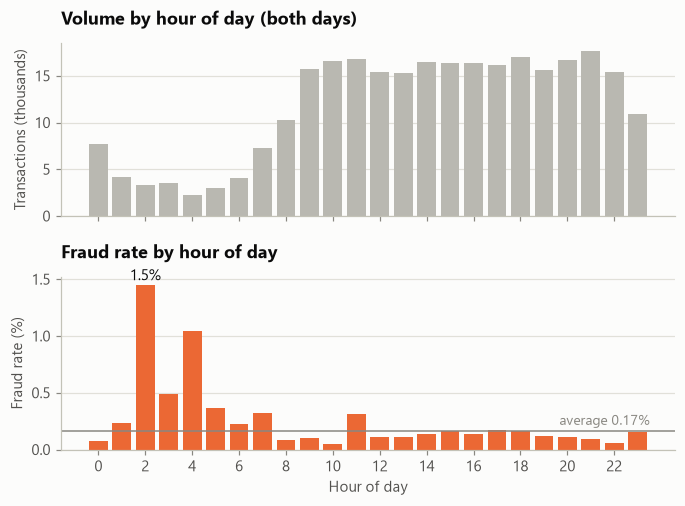

Peak: hour 2, fraud rate 1.45% = 9x the average.


In [7]:
hourly = clean.assign(hour=hour_of_day(clean["Time"]).astype(int)).groupby("hour")["Class"].agg(transactions="size", frauds="sum")
hourly["fraud_rate"] = hourly["frauds"] / hourly["transactions"]
overall = clean["Class"].mean()

fig, (top, bottom) = plt.subplots(2, 1, figsize=(7.2, 4.8), sharex=True, gridspec_kw={"hspace": 0.35})
top.bar(hourly.index, hourly["transactions"] / 1000, color=GREY, width=0.8)
top.set_ylabel("Transactions (thousands)")
top.set_title("Volume by hour of day (both days)")
bottom.bar(hourly.index, 100 * hourly["fraud_rate"], color=ORANGE, width=0.8)
bottom.axhline(100 * overall, color=MUTED, linewidth=1)
bottom.text(23.5, 100 * overall + 0.05, f"average {overall:.2%}", ha="right", color=MUTED, fontsize=9)
peak = hourly["fraud_rate"].idxmax()
bottom.text(peak, 100 * hourly.loc[peak, "fraud_rate"] + 0.04, f"{hourly.loc[peak, 'fraud_rate']:.1%}", ha="center", color=INK)
bottom.set_ylabel("Fraud rate (%)")
bottom.set_xlabel("Hour of day")
bottom.set_title("Fraud rate by hour of day")
bottom.set_xticks(range(0, 24, 2))
for ax in (top, bottom):
    ax.grid(axis="x", visible=False)
fig.savefig(FIG / "eda_hour.png")
plt.show()

print(f"Peak: hour {peak}, fraud rate {hourly.loc[peak, 'fraud_rate']:.2%} = {hourly.loc[peak, 'fraud_rate'] / overall:.0f}x the average.")

**What we did about it.** Raw `Time` is **not** a model input: it is a running counter, so every day-2 value lies outside anything seen in training. The pipeline replaces it with hour of day, encoded on a circle (sine and cosine) so that 23:00 and 01:00 are neighbours.

## 6. A handful of the anonymised features carry most of the signal

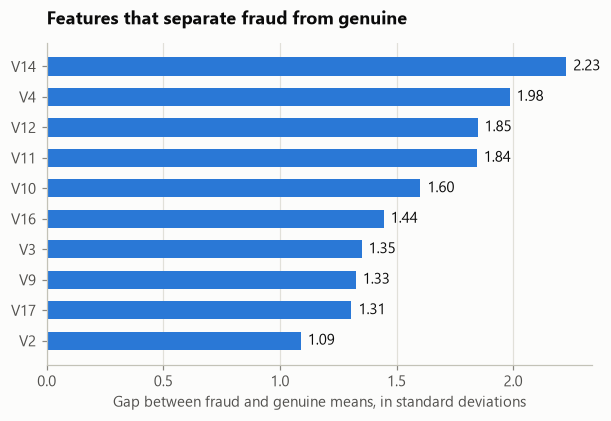

In [8]:
genuine = clean[clean["Class"] == 0]
gap = ((frauds[config.V_COLS].mean() - genuine[config.V_COLS].mean())
       / np.sqrt((frauds[config.V_COLS].var() + genuine[config.V_COLS].var()) / 2)).abs().sort_values()

fig, ax = plt.subplots(figsize=(6.4, 3.8))
top10 = gap.tail(10)
bars = ax.barh(top10.index, top10.values, color=BLUE, height=0.6)
for bar, value in zip(bars, top10.values):
    ax.text(value + 0.03, bar.get_y() + bar.get_height() / 2, f"{value:.2f}", va="center", color=INK)
ax.set_xlabel("Gap between fraud and genuine means, in standard deviations")
ax.set_title("Features that separate fraud from genuine")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "eda_separation.png")
plt.show()

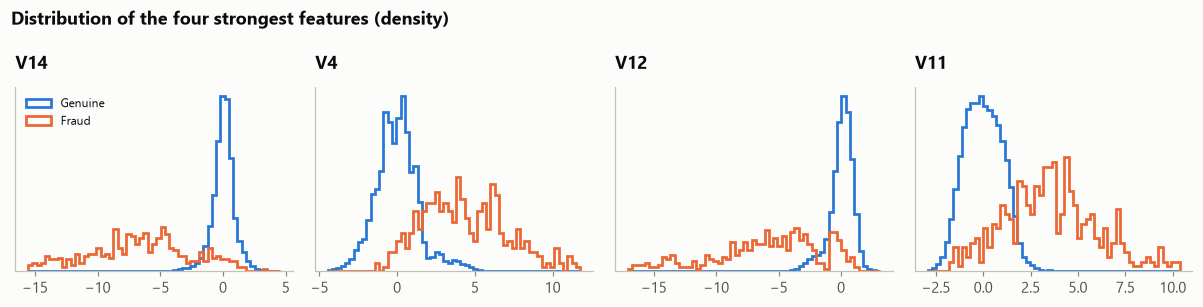

In [9]:
strongest = list(gap.tail(4).index[::-1])
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), sharey=False)
for ax, feature in zip(axes, strongest):
    lo, hi = np.percentile(clean[feature], [0.05, 99.95])
    lo, hi = min(lo, frauds[feature].quantile(0.02)), max(hi, frauds[feature].quantile(0.98))
    bins = np.linspace(lo, hi, 60)
    ax.hist(genuine[feature], bins=bins, density=True, histtype="step", color=BLUE, linewidth=1.8, label="Genuine")
    ax.hist(frauds[feature], bins=bins, density=True, histtype="step", color=ORANGE, linewidth=1.8, label="Fraud")
    ax.set_title(feature)
    ax.set_yticks([])
    ax.grid(visible=False)
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Distribution of the four strongest features (density)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "eda_distributions.png")
plt.show()

**What we did about it.** These are the features that show up as the *reasons* on each alert. Because they are anonymised, a reason is phrased honestly ("V14 is lower than 99.9% of genuine transactions") rather than pretending to a business meaning; the issuer can map each component back to its raw fields.

## 7. Scale check

In [10]:
spread = clean[[*config.V_COLS, "Amount"]].agg(["mean", "std"]).T.round(2)
print(f"V-features: means all within +/-{spread.loc[config.V_COLS, 'mean'].abs().max():.2f} of zero, "
      f"standard deviations from {spread.loc[config.V_COLS, 'std'].min():.2f} to {spread.loc[config.V_COLS, 'std'].max():.2f}.")
print(f"Amount: mean {spread.loc['Amount', 'mean']:.2f}, standard deviation {spread.loc['Amount', 'std']:.2f}.")

V-features: means all within +/-0.01 of zero, standard deviations from 0.33 to 1.95.
Amount: mean 88.47, standard deviation 250.40.


**What we did about it.** The V-features are already centred. `Amount` is on a completely different scale, so the logistic-regression pipeline standardises all inputs (the scaler is fitted on training rows only, inside the pipeline). Tree models do not need scaling.

## Summary: traps found and how each is handled

| # | Finding | Why it matters | Handling |
|---|---------|----------------|----------|
| 1 | Fraud is under 0.2% of transactions | Accuracy near 99.8% for a model that catches nothing | PR-AUC and precision/recall at 200 alerts; accuracy never used |
| 2 | Exact duplicate rows | Copies in both train and test inflate scores | Duplicates removed before any split |
| 3 | Two days, more frauds than review slots on day 1 | Recall is capped by staffing, not only by the model | Train on day 1, test on day 2; capacity planner |
| 4 | Fraud amounts are small | "Largest first" review finds almost nothing | Log amount; micro-amount reason; business baseline in the comparison |
| 5 | Fraud rate peaks overnight; `Time` is a counter | Raw `Time` cannot generalise to a new day | Hour of day (cyclical) replaces raw `Time` |
| 6 | A few V-features dominate | They drive both the score and the explanation | Per-alert reasons from exact SHAP contributions |
| 7 | Resampling can leak (see the model step) | SMOTE before the split puts synthetic copies of test frauds in training | SMOTE only inside the training fold; the wrong way is run once to measure the inflation |

**Caveats we cannot fix from here.** The PCA behind `V1`-`V28` was fitted by the data provider on the full file, test rows included, which is a mild upstream leak. Two days is also too short to see weekly patterns or fraud tactics changing, so the first production task is monitoring.